
# 03 - Closed-set Baselines and Model Selection

**Input:** `clap_embeddings.npz` (512-dimensional frozen CLAP) and `handcrafted_features.csv` (36 acoustic features). Both represent the same 3,000 audio clips with prompt-grouped splits.

**Goal:** Compare Logistic Regression, SVM and k-NN on both representations, include a DummyClassifier, select the winner using validation Macro F1, and report its final test metrics once. Detailed confusion matrices, per-class analysis and example mistakes belong to `04-error-analysis.ipynb`.

**Outputs:** `results/baseline_comparison.csv`, `results/baseline_test_metrics.json`, `results/clap_logreg_predictions.csv`.

In [22]:
from pathlib import Path
import os

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
PROJECT_ROOT


WindowsPath('c:/Users/Sofiia/UCU/year3/semester1/AI/AI-vs-Original-Music-Classification')


## Loading CLAP Embeddings

The dataset contains 3,000 audio tracks from 5 music generators, with each track represented by a 512-dimensional CLAP embedding.

The file also includes track IDs, generator labels, and predefined data splits.


In [23]:
import numpy as np
import pandas as pd
from IPython.display import display
from ai_music_origin.config import load_config
from ai_music_origin.models import build_logistic_regression, build_svm, build_knn, build_baseline
from ai_music_origin.evaluate import compute_metrics

In [24]:
with np.load(PROJECT_ROOT / 'data/interim/clap_embeddings.npz', allow_pickle=True) as saved:
    embeddings = saved['embeddings']
    track_ids = saved['track_ids'].astype(str)
    generators = saved['generators'].astype(str)
    splits = saved['splits'].astype(str)
metadata = pd.DataFrame({'track_id': track_ids, 'generator': generators, 'split': splits})
class_names = sorted(np.unique(generators).tolist())
config = load_config(PROJECT_ROOT / 'config/default.yaml')
print("Loaded CLAP embeddings")

Loaded CLAP embeddings


In [25]:
train_ids = set(metadata.loc[metadata["split"] == "train", "track_id"])
val_ids = set(metadata.loc[metadata["split"] == "val", "track_id"])
test_ids = set(metadata.loc[metadata["split"] == "test", "track_id"])

assert train_ids.isdisjoint(val_ids), "Train/Validation leakage!"
assert train_ids.isdisjoint(test_ids), "Train/Test leakage!"
assert val_ids.isdisjoint(test_ids), "Validation/Test leakage!"

print("No track_id overlap between train, validation and test.")

No track_id overlap between train, validation and test.


In [26]:
train_mask, val_mask, test_mask = (splits == s for s in ('train','validation','test'))
X_train, X_val, X_test = embeddings[train_mask], embeddings[val_mask], embeddings[test_mask]
y_train, y_val, y_test = generators[train_mask], generators[val_mask], generators[test_mask]
print("Loaded predefined splits.")

Loaded predefined splits.


## Prepare three baseline classifiers on CLAP

Logistic Regression, SVM and k-NN

In [27]:
clap_models = {
    'Logistic Regression': build_logistic_regression(config),
    'SVM': build_svm(config),
    'k-NN': build_knn(config),
}
model_results = {}
trained_models = {}
for name, model in clap_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    model_results[name] = compute_metrics(y_val, pred, labels=class_names)
    trained_models[name] = model
print('CLAP validation results ready.')

CLAP validation results ready.


## Prepare three baseline classifiers on handcrafted features

In [28]:
handcrafted_df = pd.read_csv(PROJECT_ROOT / 'data/interim/handcrafted_features.csv')
handcrafted_df['track_id'] = handcrafted_df['track_id'].astype(str)

Compare metadata between CLAP and handcrafted features

In [29]:
key_columns = ["track_id", "generator"]
clap_meta = metadata[["track_id", "generator", "split"]].copy()
handcrafted_meta = handcrafted_df[["track_id", "generator", "split"]].copy()

matched = clap_meta.merge(
    handcrafted_meta,
    on=key_columns,
    how="outer",
    suffixes=("_clap", "_handcrafted"),
    indicator=True,
    validate="one_to_one"
)

print("Matching status:")
print(matched["_merge"].value_counts())

assert (matched["_merge"] == "both").all(), ("Some tracks are missing from one of the datasets")
assert (matched["split_clap"] == matched["split_handcrafted"]).all(), "Split mismatch between datasets"
print("\nAll 3000 tracks matched!")
print("Train/validation/test splits are identical!")


Matching status:
_merge
both          3000
left_only        0
right_only       0
Name: count, dtype: int64

All 3000 tracks matched!
Train/validation/test splits are identical!


In [30]:
feature_columns = [c for c in handcrafted_df if c not in ('track_id','generator','split')]
assert len(feature_columns) == 36
hc_train, hc_val = (handcrafted_df['split'] == s for s in ('train','validation'))
X_train_hc = handcrafted_df.loc[hc_train, feature_columns]
X_val_hc = handcrafted_df.loc[hc_val, feature_columns]
y_train_hc = handcrafted_df.loc[hc_train, 'generator']
y_val_hc = handcrafted_df.loc[hc_val, 'generator']

In [31]:
hc_models = {
    'Logistic Regression': build_logistic_regression(config),
    'SVM': build_svm(config),
    'k-NN': build_knn(config),
}
hc_results = {}
hc_trained_models = {}
for name, model in hc_models.items():
    model.fit(X_train_hc, y_train_hc)
    pred = model.predict(X_val_hc)
    hc_results[name] = compute_metrics(y_val_hc, pred, labels=class_names)
    hc_trained_models[name] = model
print('Handcrafted validation results ready.')

Handcrafted validation results ready.


**Model-comparison table**

In [32]:
all_results = []
for feature_type, results in [("CLAP embeddings", model_results), ("Handcrafted features", hc_results)]:
    for model_name, metrics in results.items():
        all_results.append({
            "Features": feature_type,
            "Model": model_name,
            "Accuracy": metrics["accuracy"],
            "Balanced Accuracy": metrics["balanced_accuracy"],
            "Macro F1": metrics["macro_f1"],
            "Macro Precision": metrics["macro_precision"],
            "Macro Recall": metrics["macro_recall"],
        })

final_comparison = pd.DataFrame(all_results)
final_comparison = final_comparison.sort_values(by="Macro F1", ascending=False)
display(final_comparison.round(4))


,Features,Model,Accuracy,Balanced Accuracy,Macro F1,Macro Precision,Macro Recall
0,CLAP embeddings,Logistic Regression,0.8711,0.8711,0.8713,0.8732,0.8711
1,CLAP embeddings,SVM,0.8689,0.8689,0.8685,0.8696,0.8689
4,Handcrafted features,SVM,0.8222,0.8222,0.8209,0.8218,0.8222
2,CLAP embeddings,k-NN,0.7911,0.7911,0.7921,0.8026,0.7911
3,Handcrafted features,Logistic Regression,0.7689,0.7689,0.7657,0.7697,0.7689
5,Handcrafted features,k-NN,0.7178,0.7178,0.7183,0.7228,0.7178


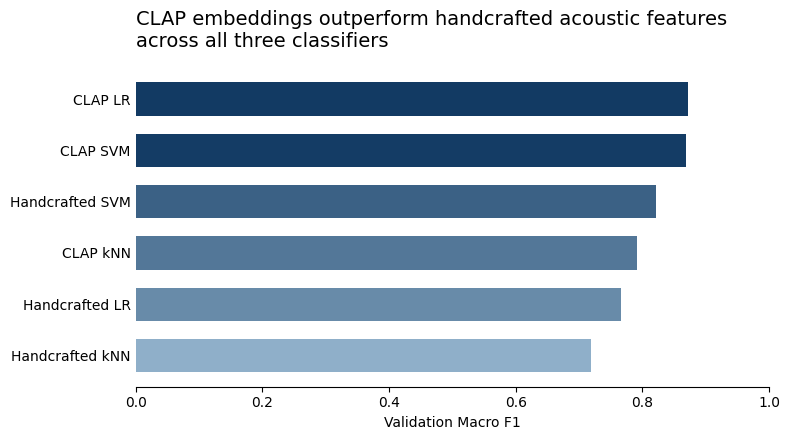

In [33]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

results = final_comparison.copy()

model_names = {
    "Logistic Regression": "LR",
    "SVM": "SVM",
    "k-NN": "kNN"
}

feature_names = {
    "CLAP embeddings": "CLAP",
    "Handcrafted features": "Handcrafted"
}

results["Combination"] = (
    results["Features"].replace(feature_names)
    + " "
    + results["Model"].replace(model_names)
)

results = results.sort_values("Macro F1", ascending=False)

cmap = mcolors.LinearSegmentedColormap.from_list(
    "custom_blue",
    ["#8FAFC9", "#123A63"]
)

norm = mcolors.Normalize(
    vmin=results["Macro F1"].min(),
    vmax=results["Macro F1"].max()
)

colors = cmap(norm(results["Macro F1"]))

plt.figure(figsize=(8, 4.5))

plt.barh(
    results["Combination"],
    results["Macro F1"],
    color=colors,
    height=0.65
)

plt.xlabel("Validation Macro F1")
plt.title(
    "CLAP embeddings outperform handcrafted acoustic features\n"
    "across all three classifiers",
    fontsize=14,
    pad=15,
    loc="left"
)
plt.xlim(0, 1)
plt.gca().invert_yaxis()

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["left"].set_visible(False)
plt.tick_params(axis="y", length=0)

plt.tight_layout()

figures_dir = PROJECT_ROOT / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "baseline_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Dummy Majority-Class Baseline

DummyClassifier is used as a simple reference model.

It always predicts the most frequent class without learning from the audio features.

The dataset contains five balanced classes, so the expected accuracy is 20%.

This baseline helps show whether the trained classifiers perform better than a simple prediction strategy.


In [34]:
from ai_music_origin.models import build_baseline

dummy_model = build_baseline()
dummy_model.fit(X_train, y_train)
dummy_pred = dummy_model.predict(X_val)

dummy_metrics = compute_metrics(
    y_val,
    dummy_pred,
    labels=class_names
)

print("DummyClassifier — Validation Results")

for metric, value in dummy_metrics.items():
    if metric != "confusion_matrix":
        print(f"{metric}: {value:.4f}")


DummyClassifier — Validation Results
accuracy: 0.2000
balanced_accuracy: 0.2000
macro_f1: 0.0667
macro_precision: 0.0400
macro_recall: 0.2000



## 11. Final Test Evaluation

Logistic Regression with CLAP embeddings is selected based on the highest validation Macro F1-score.

The selected model is evaluated on the independent test set, which was not used for training or model selection.

The final test Macro F1-score is 0.8378.


In [35]:
best_row = final_comparison.loc[
    final_comparison["Macro F1"].idxmax()
]

best_model_name = best_row["Model"]
best_feature_type = best_row["Features"]

if best_feature_type == "CLAP embeddings":
    best_model = trained_models[best_model_name]
    X_final_test = X_test
    y_final_test = y_test

else:
    best_model = hc_trained_models[best_model_name]
    hc_test = handcrafted_df["split"] == "test"
    X_final_test = handcrafted_df.loc[hc_test, feature_columns]
    y_final_test = handcrafted_df.loc[hc_test, "generator"]

y_test_pred = best_model.predict(X_final_test)

test_metrics = compute_metrics(
    y_final_test,
    y_test_pred,
    labels=class_names
)

print("Final Test Results")
print("Model:", best_model_name)
print("Features:", best_feature_type)

for metric, value in test_metrics.items():
    if metric != "confusion_matrix":
        print(f"{metric}: {value:.4f}")


Final Test Results
Model: Logistic Regression
Features: CLAP embeddings
accuracy: 0.8378
balanced_accuracy: 0.8378
macro_f1: 0.8378
macro_precision: 0.8380
macro_recall: 0.8378


In [36]:
if best_feature_type == "CLAP embeddings":
    X_final_train = X_train
    y_final_train = y_train
    val_metrics = model_results[best_model_name]
else:
    X_final_train = X_train_hc
    y_final_train = y_train_hc
    val_metrics = hc_results[best_model_name]

train_pred = best_model.predict(X_final_train)

train_metrics = compute_metrics(
    y_final_train,
    train_pred,
    labels=class_names
)

performance_comparison = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Macro F1": [
        train_metrics["macro_f1"],
        val_metrics["macro_f1"],
        test_metrics["macro_f1"]
    ]
})

display(performance_comparison.round(4))

print(
    "Train - Validation gap:",
    round(
        train_metrics["macro_f1"] - val_metrics["macro_f1"], 4
    )
)

print(
    "Validation - Test gap:",
    round(
        val_metrics["macro_f1"] - test_metrics["macro_f1"], 4
    )
)


,Dataset,Macro F1
0,Train,0.9943
1,Validation,0.8713
2,Test,0.8378


Train - Validation gap: 0.1229
Validation - Test gap: 0.0335


In [37]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

figures_dir = PROJECT_ROOT / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

clap_filename_map = {
    "Logistic Regression": "logistic_regression_confusion_matrix.png",
    "SVM": "svm_confusion_matrix.png",
    "k-NN": "k-nn_confusion_matrix.png"
}

for model_name, model in trained_models.items():
    y_val_pred = model.predict(X_val)

    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_val_pred,
        labels=class_names,
        display_labels=class_names,
        cmap="Blues",
        ax=ax,
        xticks_rotation=45
    )

    ax.set_title(f"{model_name} — Validation Confusion Matrix")
    plt.tight_layout()

    plt.savefig(
        figures_dir / clap_filename_map[model_name],
        dpi=300,
        bbox_inches="tight"
    )
    plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_final_test,
    y_test_pred,
    labels=class_names,
    display_labels=class_names,
    cmap="Blues",
    ax=ax,
    xticks_rotation=45
)

ax.set_title(f"{best_model_name} ({best_feature_type}) — Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    figures_dir / "clap_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close(fig)

print("Saved:")
print("logistic_regression_confusion_matrix.png")
print("svm_confusion_matrix.png")
print("k-nn_confusion_matrix.png")
print("clap_test_confusion_matrix.png")

Saved:
logistic_regression_confusion_matrix.png
svm_confusion_matrix.png
k-nn_confusion_matrix.png
clap_test_confusion_matrix.png



### Generalization Analysis

The train-validation Macro F1 gap of 0.1229 suggests possible
overfitting. The validation-test gap is 0.0335, indicating a
moderate decrease in performance on unseen data.

The selected model still achieves a test Macro F1 of 0.8378.


## 12. Saving Results

The experiment results are saved in the `results/` directory.

The output includes:
- `baseline_comparison.csv` — validation results for all six model combinations.
- `baseline_test_metrics.json` — final test metrics of the selected model.
- `baseline_test_confusion_matrix.png` — confusion matrix for the final test.

These files make the results available for further analysis and comparison.


In [38]:
import json

results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

final_comparison.to_csv(
    results_dir / "baseline_comparison.csv",
    index=False
)

validation_metrics = (
    model_results[best_model_name]
    if best_feature_type == "CLAP embeddings"
    else hc_results[best_model_name]
)

with open(
    results_dir / "baseline_test_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump({
        "model": best_model_name,
        "features": best_feature_type,
        "validation_macro_f1": float(validation_metrics["macro_f1"]),
        "test_metrics": {
            key: (
                value.tolist()
                if isinstance(value, np.ndarray)
                else value
                if isinstance(value, list)
                else float(value)
            )
            for key, value in test_metrics.items()
        }
    }, f, indent=2)

clap_logreg = trained_models["Logistic Regression"]

validation_predictions = clap_logreg.predict(X_val)
test_predictions = clap_logreg.predict(X_test)

validation_confidence = clap_logreg.predict_proba(X_val).max(axis=1)
test_confidence = clap_logreg.predict_proba(X_test).max(axis=1)

prediction_rows = pd.DataFrame({
    "track_id": np.concatenate([
        track_ids[val_mask],
        track_ids[test_mask]
    ]).astype(str),
    "generator": np.concatenate([y_val, y_test]),
    "split": (
        ["validation"] * len(y_val)
        + ["test"] * len(y_test)
    ),
    "predicted_generator": np.concatenate([
        validation_predictions,
        test_predictions
    ]),
    "predicted_probability": np.concatenate([
        validation_confidence,
        test_confidence
    ])
})

prediction_rows.to_csv(
    results_dir / "clap_logreg_predictions.csv",
    index=False
)

print("Saved baseline_comparison.csv")
print("Saved baseline_test_metrics.json")
print("Saved clap_logreg_predictions.csv")


Saved baseline_comparison.csv
Saved baseline_test_metrics.json
Saved clap_logreg_predictions.csv


## Conclusion

We tested three machine learning models: Logistic Regression, SVM, and k-NN. We used two types of audio features: handcrafted features (36 features) and CLAP embeddings (512 features).

We used the same train, validation, and test split (70%/15%/15%) for all models to make the comparison fair.

### Main Results

- CLAP embeddings gave better results than handcrafted features for all three models.
- **Logistic Regression with CLAP embeddings** was the best model, with a validation Macro F1-score of **0.8713**.
- For handcrafted features, **SVM** performed best, with a Macro F1-score of **0.8209**.
- k-NN had lower results than the other models.
- DummyClassifier had a Macro F1-score of only **0.0667**, showing that our models performed much better than a simple baseline.

### Final Test Results

We tested the best model, Logistic Regression with CLAP embeddings, on the test dataset.

- Accuracy: **0.8378**
- Balanced Accuracy: **0.8378**
- Macro F1: **0.8378**
- Macro Precision: **0.8380**
- Macro Recall: **0.8378**

The test results were slightly lower than the validation results, but the model still performed well on new data.

### Overall Conclusion

Our experiments showed that **CLAP embeddings work better than handcrafted features** for identifying which AI model generated a music track.
